# Phân loại hoa Iris với Keras / TensorFlow
Dự án xây dựng mô hình mạng nơ-ron truyền thẳng (Multi-Layer Perceptron) để phân loại 3 loài hoa Iris.

In [81]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

# Cố định ngẫu nhiên triệt để (Reproducibility)
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()


### 1. Tải dataset Iris

In [82]:
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)  # Chuyển thành mảng 2 chiều (N, 1) cho OneHotEncoder
target_names = iris.target_names

### 2. Chia tập Train và Test (Tránh Data Leakage)

In [83]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y  # Giữ nguyên tỷ lệ 3 loài hoa ở cả 2 tập
)

### 3. Tiền xử lý dữ liệu
- `StandardScaler` cho đặc trưng đầu vào X
- `OneHotEncoder` cho nhãn y

In [84]:
# Chuẩn hóa đặc trưng đầu vào
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# One-hot encode nhãn
encoder = OneHotEncoder()
y_train_encoded = encoder.fit_transform(y_train).toarray()
y_test_encoded = encoder.transform(y_test).toarray()

### 4. Xây dựng mô hình Deep Learning

In [85]:
model = Sequential([
    Input(shape=(4,)),              # Lớp đầu vào nhận 4 đặc trưng của hoa
    Dense(10, activation='relu'),   # Lớp ẩn 1 (Hidden layer 1)
    Dense(10, activation='relu'),   # Lớp ẩn 2 (Hidden layer 2)
    Dense(3, activation='softmax')  # Lớp đầu ra cho 3 loài hoa
])

model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_24 (Dense)                │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 3)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 193 (772.00 B)

 Trainable params: 193 (772.00 B)

 Non-trainable params: 0 (0.00 B)

### 5. Cấu hình cách học (Compile)

In [86]:
model.compile(
    optimizer=Adam(learning_rate=0.01),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


### 6. Huấn luyện mô hình & Theo dõi lịch sử (Training History)

In [87]:
history = model.fit(
    X_train_scaled,
    y_train_encoded,
    epochs=50,
    validation_data=(X_test_scaled, y_test_encoded),
    verbose=0
)
print("Huấn luyện hoàn tất qua 50 epochs!")

Huấn luyện hoàn tất qua 50 epochs!


### 7. Trực quan hóa quá trình học (Loss & Accuracy curves)

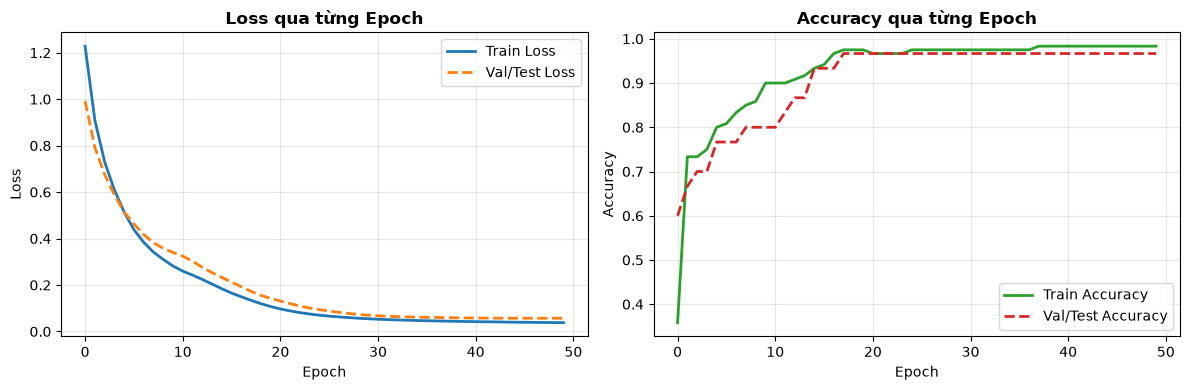

In [88]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Loss
ax1.plot(history.history['loss'], label='Train Loss', color='#1f77b4', linewidth=2)
ax1.plot(history.history['val_loss'], label='Val/Test Loss', color='#ff7f0e', linestyle='--', linewidth=2)
ax1.set_title('Loss qua từng Epoch', fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Accuracy
ax2.plot(history.history['accuracy'], label='Train Accuracy', color='#2ca02c', linewidth=2)
ax2.plot(history.history['val_accuracy'], label='Val/Test Accuracy', color='#d62728', linestyle='--', linewidth=2)
ax2.set_title('Accuracy qua từng Epoch', fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 8. Đánh giá mô hình trên tập kiểm thử (Test Set)

In [89]:
loss, accuracy = model.evaluate(X_test_scaled, y_test_encoded, verbose=0)
print(f"Test Loss: {loss:.4f}")
print(f"DL Accuracy: {accuracy:.4f}")

Test Loss: 0.0571
DL Accuracy: 0.9667


### 9. Báo cáo phân loại chi tiết & Ma trận nhầm lẫn (Confusion Matrix)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
Báo cáo phân loại:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



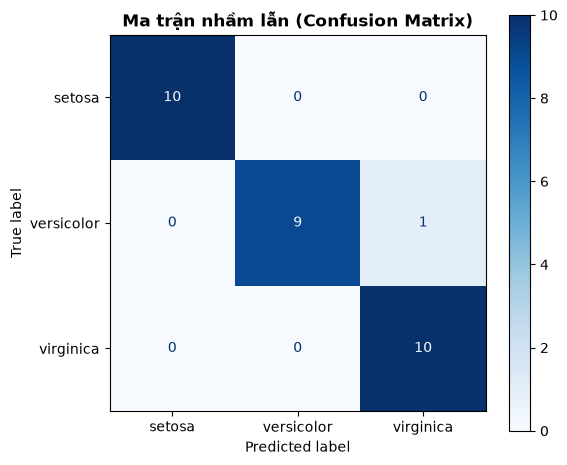

In [90]:
y_pred_prob = model.predict(X_test_scaled)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = y_test.flatten()

print("Báo cáo phân loại:")
print(classification_report(y_true, y_pred, target_names=target_names))

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Ma trận nhầm lẫn (Confusion Matrix)', fontweight='bold')
plt.tight_layout()
plt.show()